In [23]:
import numpy as np
import rasterio 
import os
import matplotlib.pyplot as plt
from tqdm import tqdm
import pathlib

In [24]:
#|export

def save_raster(
    img:np.ndarray , # ndarray image
    number_of_bands: int , #number of  bands
    transf:tuple ,#transform function of the raster
    paths:str ,#save path raster
    tiff_name:str ,#name of specific file
    crs_img:rasterio.crs.CRS,
    ):  
    
    '''
    Function to save raster in requested path

    '''

    savedir=pathlib.Path(paths)
    savedir.mkdir(parents=True,exist_ok=True)


    with rasterio.open(savedir /tiff_name, 
                                   'w',
                                   driver='COG',
                                   height=img.shape[1],
                                   width=img.shape[2],
                                   count=number_of_bands,
                                   dtype=img.dtype,
                                   crs=crs_img,
                                   nodata=None, # change if data has nodata value
                                   transform=transf) as dst:

            for n in np.arange(0,number_of_bands):
                  dst.write(img[n,:,:],int(n+1))   
                    
    return None

In [25]:
def select_bands_rgb(
    input_dir: str , #the direcotry where images are stored
    output_dir: str, #the directory where the results images to be saved
    r_band: int ,
    g_band: int,
    b_band: int,
    
):
    for filename in tqdm(os.listdir(input_dir), desc="Processing rasters"):
        # for filename in os.listdir(input_dir):
        # print(filename)
        input_path = os.path.join(input_dir, filename)
        output_path = os.path.join(output_dir, filename)  
        
        os.makedirs(os.path.dirname(output_path), exist_ok=True)



        with rasterio.open(input_path) as src:
            arr = src.read()
            
            # Convert to zero-based indices
            bands = [r_band - 1, g_band - 1, b_band - 1]
            
            # Validate bands
            for b in bands:
                if b < 0 or b >= src.count:
                    raise ValueError(f"Band index {b+1} is out of range (1-{src.count}) in {filename}")
            
            # Extract selected bands
            selected_data = arr[bands, :, :]
            
       
            
            save_raster(
                img = selected_data,
                number_of_bands = 3, 
                transf = src.transform,
                paths = output_dir,
                tiff_name = filename,
                crs_img= src.crs)



In [27]:
test = select_bands_rgb(
    input_dir="/home/jovyan/work/imagery/test_DONT_REMOVE/test_brian/run3/4904/",
    output_dir="/home/jovyan/work/imagery/test_DONT_REMOVE/test_brian/test_select_bands1",
    r_band =3,
    g_band=2,
    b_band=1)

Processing rasters:  15%|█▌        | 2/13 [01:10<06:27, 35.23s/it]


KeyboardInterrupt: 

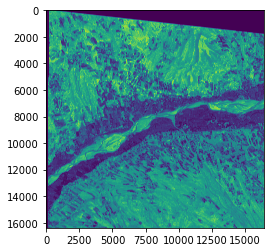

In [18]:
plt.imshow(test[1,:,:])

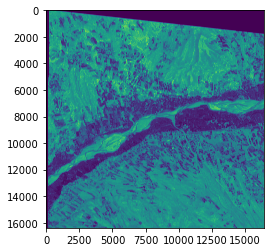

In [19]:
plt.imshow(test[0,:,:])

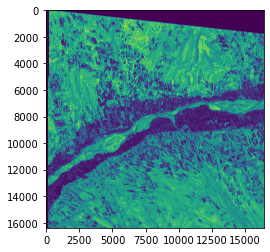

In [20]:
plt.imshow(test[2,:,:])

In [10]:
import rasterio
test=rasterio.open("/home/jovyan/work/imagery/test_DONT_REMOVE/test_brian/test_ndbi/WV02_250729_8bands_kandahar/25JUL29062634-S3DS-200009789240_01_P001.TIF")

In [11]:
test.count

8

In [4]:
import geopandas as gpd
num = 9038
gdf = gpd.read_file(f"/home/jovyan/work/predictions/test/run6/{num}/geojson/predicted_buildings.geojson")
gdf.to_file(f"/home/jovyan/work/predictions/test/run6/{num}/geojson/{num}_bldgs.gpkg")

/opt/conda/lib/python3.9/site-packages/geopandas/io/file.py:362: FutureWarning: pandas.Int64Index is deprecated and will be removed from pandas in a future version. Use pandas.Index with the appropriate dtype instead.
  pd.Int64Index,
